In [ ]:
import pandas as pd
import numpy as np
import kagglehub

path = kagglehub.dataset_download("msambare/fer2013")
print(path)

Using Colab cache for faster access to the 'fer2013' dataset.
/kaggle/input/fer2013


In [ ]:
import os
os.listdir(path)

['test', 'train']

In [ ]:
test_path = os.path.join(path,"test")
train_path = os.path.join(path,"train")

In [ ]:
print(os.listdir(train_path))
print(os.listdir(test_path))

['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']
['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']


In [ ]:
happy_path = os.path.join(train_path,"happy")
angry_path = os.path.join(train_path,"angry")
sad_path = os.path.join(train_path,"sad")

os.listdir(happy_path)
os.listdir(angry_path)
os.listdir(sad_path)

['Training_89959053.jpg',
 'Training_20087082.jpg',
 'Training_13633741.jpg',
 'Training_87971378.jpg',
 'Training_41661309.jpg',
 'Training_54602400.jpg',
 'Training_40233889.jpg',
 'Training_13307281.jpg',
 'Training_84900551.jpg',
 'Training_22093911.jpg',
 'Training_56613804.jpg',
 'Training_36513747.jpg',
 'Training_71334011.jpg',
 'Training_9648154.jpg',
 'Training_82887890.jpg',
 'Training_51852861.jpg',
 'Training_73491794.jpg',
 'Training_56768889.jpg',
 'Training_84736751.jpg',
 'Training_25257752.jpg',
 'Training_89368042.jpg',
 'Training_42398856.jpg',
 'Training_91979653.jpg',
 'Training_55881751.jpg',
 'Training_89835262.jpg',
 'Training_70207644.jpg',
 'Training_90819454.jpg',
 'Training_71451863.jpg',
 'Training_96207457.jpg',
 'Training_11815662.jpg',
 'Training_75444602.jpg',
 'Training_68810853.jpg',
 'Training_73899462.jpg',
 'Training_76572193.jpg',
 'Training_96197039.jpg',
 'Training_45559063.jpg',
 'Training_10274140.jpg',
 'Training_72762537.jpg',
 'Training_62

In [ ]:
print("Happy images:", len(os.listdir(happy_path)))
print("angry images:", len(os.listdir(angry_path)))
print("sad images:", len(os.listdir(sad_path)))

Happy images: 7215
angry images: 3995
sad images: 4830


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range=20,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
training_set = train_datagen.flow_from_directory(
    train_path,
    target_size=(48,48),
    color_mode='grayscale',
    batch_size=32,
    class_mode='categorical',
    classes=['happy','sad','angry']
)

test_set = test_datagen.flow_from_directory(
    test_path,
    target_size=(48,48),
    color_mode='grayscale',
    batch_size=32,
    class_mode='categorical',
    classes=['happy','sad','angry']
)

Found 16040 images belonging to 3 classes.
Found 3979 images belonging to 3 classes.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
model=Sequential()
model.add(Conv2D(32, kernel_size=3, activation='relu', input_shape=(48,48,1)))
model.add(MaxPooling2D(pool_size=2))
model.add(Conv2D(filters=64, kernel_size=3, activation='relu'))
model.add(MaxPooling2D(pool_size=2))
model.add(Conv2D(filters=64, kernel_size=3, activation='relu'))
model.add(MaxPooling2D(pool_size=2))
model.add(Flatten()) # Added Flatten layer here
model.add(Dense(units=128, activation='relu'))
model.add(Dense(units=3, activation='softmax'))
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(
    training_set,
    epochs=15,
    validation_data=test_set
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
502/502 ━━━━━━━━━━━━━━━━━━━━ 83s 155ms/step - accuracy: 0.4832 - loss: 1.0280 - val_accuracy: 0.5363 - val_loss: 0.9347
Epoch 2/15
502/502 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - accuracy: 0.5546 - loss: 0.9285 - val_accuracy: 0.5954 - val_loss: 0.8345
Epoch 3/15
502/502 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - accuracy: 0.6031 - loss: 0.8480 - val_accuracy: 0.6514 - val_loss: 0.7553
Epoch 4/15
502/502 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - accuracy: 0.6464 - loss: 0.7796 - val_accuracy: 0.6869 - val_loss: 0.6927
Epoch 5/15
502/502 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - accuracy: 0.6622 - loss: 0.7428 - val_accuracy: 0.6999 - val_loss: 0.6814
Epoch 6/15
502/502 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - accuracy: 0.6837 - loss: 0.7113 - val_accuracy: 0.6957 - val_loss: 0.6922
Epoch 7/15
502/502 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - accuracy: 0.6901 - loss: 0.6904 - val_accuracy: 0.7153 - val_loss: 0.6430
Epoch 8/15
502/502 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.7016 - loss: 0.6683 -

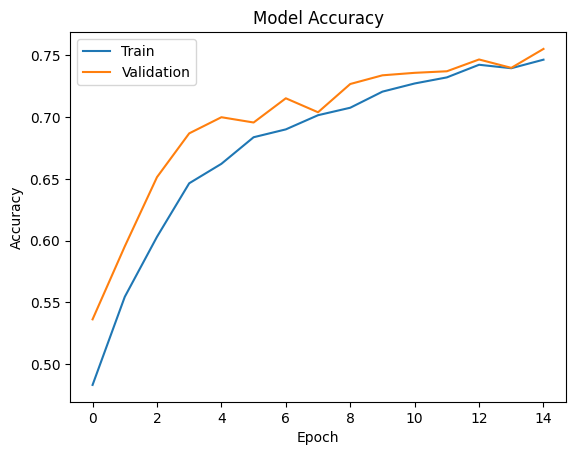

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

plt.show()

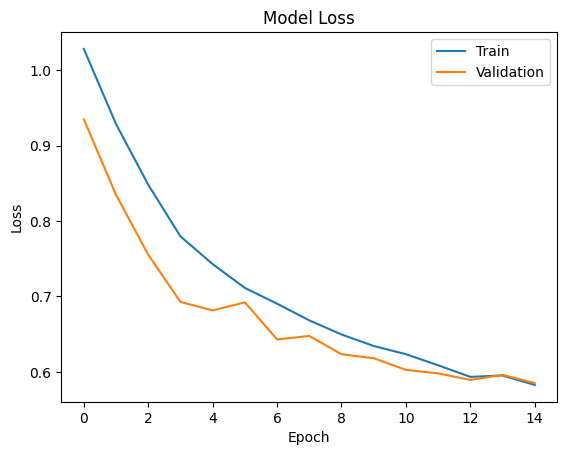

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])

plt.show()

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image
import os

# Get the first image file from the happy_path
first_happy_image = os.path.join(happy_path, os.listdir(happy_path)[0])

img = image.load_img(first_happy_image, target_size=(48,48), color_mode='grayscale')
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# You can now use img_array for prediction with your model
# For example:
# predictions = model.predict(img_array)
# print(predictions)

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import io

print("Please upload an image file:")
uploaded = files.upload()

for fn in uploaded.keys():
  # Read the image from bytes
  img_bytes = uploaded[fn]
  img = image.load_img(io.BytesIO(img_bytes), target_size=(48,48), color_mode='grayscale')
  img_array = image.img_to_array(img)
  img_array = np.expand_dims(img_array, axis=0)
  img_array = img_array / 255.0
  print(f"Image '{fn}' loaded successfully!")
  # You can now use img_array for prediction with your model
  # For example:
  # predictions = model.predict(img_array)
  # print(predictions)
  break # Assuming only one file is uploaded for processing

Please upload an image file:


Saving download.jpg to download.jpg
Image 'download.jpg' loaded successfully!


In [ ]:
predictions = model.predict(img_array)

# Get the index of the predicted class
predicted_class_index = np.argmax(predictions[0])

# Get the class labels from the training_set (order matters)
class_labels = list(training_set.class_indices.keys())

# Get the predicted emotion label
predicted_emotion = class_labels[predicted_class_index]

print(f"The predicted emotion for the uploaded image is: {predicted_emotion}")
print(f"Prediction probabilities: {predictions[0]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
The predicted emotion for the uploaded image is: sad
Prediction probabilities: [0.14009964 0.7223241  0.13757634]


In [ ]:
predictions = model.predict(img_array)

# Get the index of the predicted class
predicted_class_index = np.argmax(predictions[0])

# Get the class labels from the training_set (order matters)
class_labels = list(training_set.class_indices.keys())

# Get the predicted emotion label
predicted_emotion = class_labels[predicted_class_index]

print(f"The predicted emotion for the uploaded image is: {predicted_emotion}")
print(f"Prediction probabilities: {predictions[0]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
The predicted emotion for the uploaded image is: sad
Prediction probabilities: [0.14009964 0.7223241  0.13757634]


In [ ]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode
import cv2
import numpy as np
import tensorflow as tf

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture Photo';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element. Muxy's magic!
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for button to click
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

try:
  filename = take_photo()
  print(f'Saved to {filename}')

  # Load the image using keras.preprocessing.image
  img = tf.keras.preprocessing.image.load_img(filename, target_size=(48, 48), color_mode='grayscale')
  img_array = tf.keras.preprocessing.image.img_to_array(img)
  img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
  img_array = img_array / 255.0  # Normalize

  # Make prediction
  predictions = model.predict(img_array)

  # Get the index of the predicted class
  predicted_class_index = np.argmax(predictions[0])

  # Get the class labels from the training_set
  class_labels = list(training_set.class_indices.keys())

  # Get the predicted emotion label
  predicted_emotion = class_labels[predicted_class_index]

  print(f"The predicted emotion for the live image is: {predicted_emotion}")
  print(f"Prediction probabilities: {predictions[0]}")

except Exception as err:
  # Errors will be thrown if the user does not have a webcam or denies access
  print(str(err))
  print('You did not grant access to the webcam or you do not have a webcam. Please upload an image if you wish to proceed.')

<IPython.core.display.Javascript object>

Saved to photo.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
The predicted emotion for the live image is: sad
Prediction probabilities: [0.07294196 0.6644613  0.26259682]
